# EWMA correlation : how well does it approximate the realised correlation ?

**Question.** Same study as `constant_correlation.ipynb`, with the EWMA correlation instead of a constant : for
20 baskets of two or three Euronext Paris stocks and maturities from 1 month to 5 years, is the correlation realised
over the life of the product well approximated by the EWMA correlation known at the start ?

**Model** (`ewma_correlation.py`). EWMA of the GARCH(1,1)-t standardised residuals,
Q_t = (1 − λ) e_{t−1} e_{t−1}' + λ Q_{t−1}, R_t = corr(Q_t). Its forecast of the correlation over [t, t + H) is R_t
for every H (the EWMA correlation is a martingale). λ is estimated by maximum likelihood (correlation part of the
Gaussian likelihood), one λ per basket :
- **in-sample λ** : fitted on the whole history ;
- **out-of-sample λ** : re-fitted at every date on the past only — the forecast a pricer could actually have made.

**Windows.** As in the constant study, one window every 21 days, starting after 2 years of history ; the realised
correlation is that of the daily returns over [t, t + H). The constants of the first study are recomputed on exactly
the same windows.

**Why the method of the constant study cannot be copied.** There, the statistics were compared with their
distribution under H0 "the correlation is constant", simulated. The analogue here would be "the correlation follows
the EWMA recursion". But as a data-generating process the EWMA correlation is a bounded martingale with no mean
reversion : it wanders across the whole [−1, 1] interval and is eventually absorbed at ±1 (section 6). Its H0
distribution is so wide that a test against it has almost no power. The EWMA is therefore evaluated as a
**forecast** :
1. RMSE against the realised correlation, compared with the constant and with the **noise floor** (the sampling
   noise of the realised correlation, simulated as in the constant study, that no forecast can remove) ;
2. **Diebold-Mariano** test of equal squared error, EWMA against the constant (out-of-sample) ;
3. **Mincer-Zarnowitz** regression realised = a + b · forecast, Wald test of (a, b) = (0, 1) : is the EWMA an
   unbiased forecast, and does it react to the right extent (b = 1) ?
4. the λ each horizon calls for (RMSE as a function of λ, with hindsight) ;
5. the test of the EWMA dynamics itself (section 6).

Tests 2 and 3 use Newey-West variances over the overlapping windows ; their p-values are reliable at short horizons,
optimistic at long ones (at 5 years there are only ≈ 4 independent windows), and are corrected for the 20 baskets by
Benjamini-Hochberg.

In [1]:
import os, sys, warnings
sys.path.append(os.path.abspath("."))                                   # Models/Correlation
warnings.filterwarnings("ignore", category=RuntimeWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import constant_correlation as cc
import ewma_correlation as ew

pd.set_option("display.float_format", lambda x: f"{x:.4g}")
DATA = os.path.join("..", "..", "Data", "Equity")
HORIZONS = cc.HORIZONS
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3,
                     "figure.figsize": (11, 4), "lines.linewidth": 1.2})

def half_life(lam):
    return np.log(0.5) / np.log(lam)

## 1. Data and estimated λ

In [2]:
px = pd.read_csv(os.path.join(DATA, "Universe_Daily_AdjClose.csv"), index_col="Date", parse_dates=True)
with open(os.path.join(DATA, "LAST_DOWNLOAD_UNIVERSE.txt")) as f:
    print("downloaded on", f.read().strip(), "-", px.shape[1], "stocks,", f"{px.index[0].date()} -> {px.index[-1].date()}")

results = ew.analyse_all(px, verbose=False)                            # ≈ 15 s
B = pd.concat({k: v["basket"] for k, v in results.items()}, names=["basket"]).reset_index(level=0)

def table(column):
    return B.pivot(index="basket", columns="horizon", values=column)[list(HORIZONS)].reindex(list(cc.BASKETS))

lambdas = pd.DataFrame({name: {"lambda (in-sample)": res["lambda"], "half-life (days)": half_life(res["lambda"]),
                               "oos lambda min": res["lambda_oos"].min(), "oos lambda max": res["lambda_oos"].max()}
                        for name, res in results.items()}).T
lambdas

downloaded on 2026-11-28 - 23 stocks, 2005-01-03 -> 2026-11-27


,lambda (in-sample),half-life (days),oos lambda min,oos lambda max
LVMH / Hermès,0.9776,30.59,0.9598,0.9875
LVMH / Kering,0.9907,74.05,0.97,0.9907
LVMH / Hermès / Kering,0.992,85.76,0.9741,0.992
BNP / SocGen,0.9875,55.18,0.9534,0.9995
BNP / SocGen / Crédit Agricole,0.9875,55.18,0.9534,0.993
Airbus / Safran,0.994,115,0.993,0.9995
Airbus / Safran / Thales,0.992,85.76,0.9892,0.9986
L'Oréal / Danone,0.993,99.32,0.9892,0.9967
L'Oréal / Pernod,0.994,115,0.992,0.9975
Vinci / Bouygues / Saint-Gobain,0.993,99.32,0.9833,0.994


## 2. EWMA forecast and realised correlation

At each date t : the EWMA correlation (forecast), the expanding-window constant, and the correlation that will be
realised over the next year [t, t + 252). The EWMA follows the recent correlation closely ; the realised one-year
correlation moves much less.

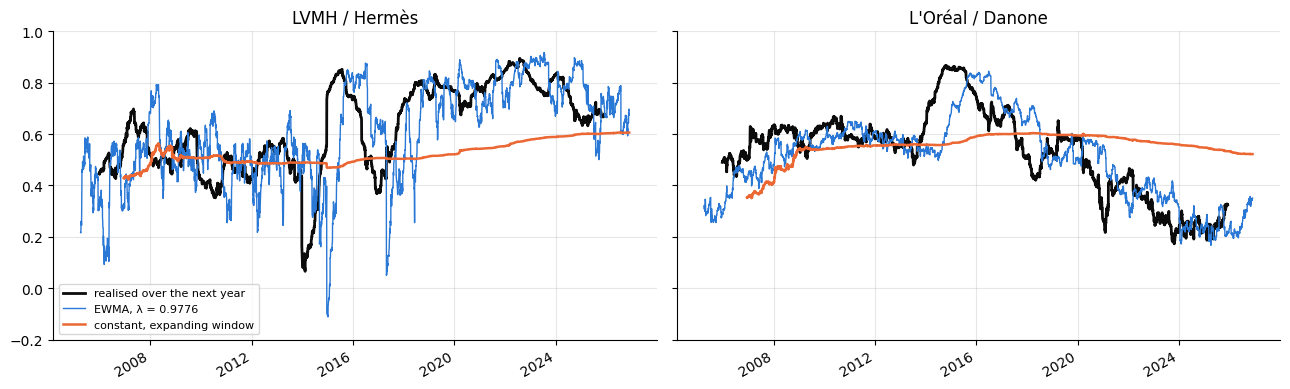

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for k, name in enumerate(["LVMH / Hermès", "L'Oréal / Danone"]):
    r = cc.basket_returns(px, cc.BASKETS[name])
    a, b = r.columns
    cc.realised_correlation(r, 252).iloc[:, 0].shift(-251).plot(ax=ax[k], color="#0b0b0b", lw=2,
                                                                label="realised over the next year")
    ew.ewma_forecast(r, results[name]["lambda"]).iloc[63:, 0].plot(ax=ax[k], color="#2a78d6", lw=1,
                                                                   label=f"EWMA, λ = {results[name]['lambda']:.4f}")
    r[a].expanding(504).corr(r[b]).plot(ax=ax[k], color="#eb6834", lw=1.8, label="constant, expanding window")
    ax[k].set_title(name); ax[k].set_ylim(-0.2, 1); ax[k].set_xlabel("")
ax[0].legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

## 3. RMSE of the EWMA forecast

RMSE between the realised correlation and the forecast, pooled over the pairs of each basket.

In [4]:
display(table("rmse ewma_oos").style.format("{:.3f}").background_gradient(cmap="Blues", axis=None, vmin=0, vmax=0.35)
        .set_caption("RMSE of the EWMA forecast, out-of-sample λ"))
display(table("ratio EWMA / constant (oos)").style.format("{:.2f}")
        .background_gradient(cmap="RdBu_r", axis=None, vmin=0.5, vmax=1.5)
        .set_caption("RMSE ratio EWMA / constant, both out-of-sample (< 1 : EWMA better)"))
summary = B.groupby("horizon", sort=False)[["rmse ewma_is", "rmse ewma_oos", "rmse const_is", "rmse const_oos",
                                             "noise floor"]].median()
summary.columns = ["EWMA, in-sample λ", "EWMA, out-of-sample λ", "constant, in-sample", "constant, out-of-sample",
                   "noise floor"]
summary.T.style.format("{:.3f}").set_caption("Median RMSE over the 20 baskets")

horizon,1m,2m,3m,6m,1y,2y,3y,5y
basket,,,,,,,,
LVMH / Hermès,0.222,0.200,0.187,0.174,0.183,0.182,0.174,0.189
LVMH / Kering,0.165,0.137,0.129,0.127,0.128,0.123,0.121,0.114
LVMH / Hermès / Kering,0.208,0.180,0.169,0.157,0.156,0.150,0.145,0.150
BNP / SocGen,0.177,0.148,0.140,0.116,0.100,0.095,0.086,0.074
BNP / SocGen / Crédit Agricole,0.173,0.148,0.137,0.120,0.111,0.111,0.111,0.112
Airbus / Safran,0.201,0.159,0.140,0.119,0.117,0.128,0.137,0.149
Airbus / Safran / Thales,0.242,0.203,0.191,0.169,0.169,0.170,0.165,0.147
L'Oréal / Danone,0.217,0.163,0.139,0.113,0.106,0.114,0.125,0.141
L'Oréal / Pernod,0.199,0.159,0.142,0.123,0.122,0.120,0.122,0.124


horizon,1m,2m,3m,6m,1y,2y,3y,5y
basket,,,,,,,,
LVMH / Hermès,0.90,0.90,0.89,0.88,0.98,1.04,0.99,1.04
LVMH / Kering,0.98,0.97,0.99,1.10,1.25,1.40,1.58,1.56
LVMH / Hermès / Kering,0.93,0.92,0.92,0.94,1.01,1.06,1.03,1.04
BNP / SocGen,1.04,1.07,1.07,1.07,1.04,1.01,0.93,0.83
BNP / SocGen / Crédit Agricole,1.05,1.09,1.12,1.18,1.21,1.26,1.28,1.28
Airbus / Safran,0.96,0.93,0.90,0.85,0.84,0.84,0.83,0.79
Airbus / Safran / Thales,0.98,0.99,1.01,1.03,1.09,1.17,1.19,1.07
L'Oréal / Danone,0.85,0.76,0.69,0.61,0.59,0.65,0.74,0.90
L'Oréal / Pernod,0.92,0.89,0.87,0.83,0.84,0.84,0.82,0.79


horizon,1m,2m,3m,6m,1y,2y,3y,5y
"EWMA, in-sample λ",0.223,0.180,0.166,0.151,0.143,0.131,0.131,0.133
"EWMA, out-of-sample λ",0.225,0.182,0.169,0.156,0.148,0.144,0.141,0.148
"constant, in-sample",0.240,0.199,0.181,0.155,0.134,0.111,0.101,0.093
"constant, out-of-sample",0.247,0.202,0.186,0.163,0.151,0.145,0.143,0.142
noise floor,0.201,0.148,0.124,0.092,0.069,0.052,0.043,0.033


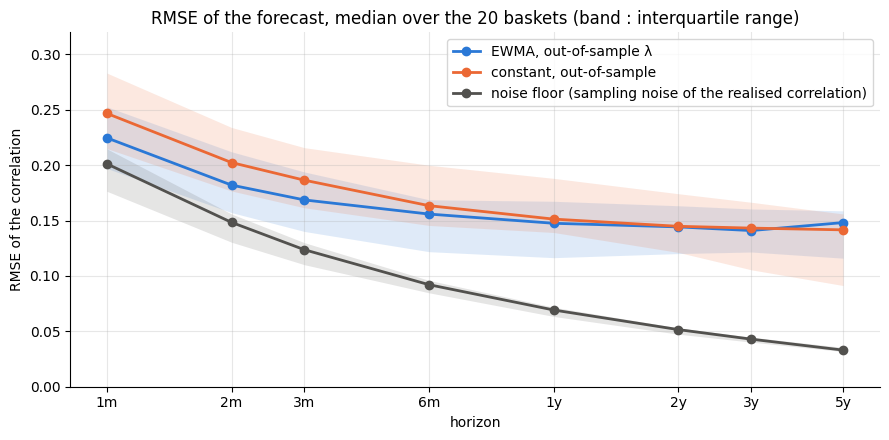

In [5]:
x = np.array(list(HORIZONS.values())) / 252
fig, ax = plt.subplots(figsize=(9, 4.5))
for col, c, label in [("rmse ewma_oos", "#2a78d6", "EWMA, out-of-sample λ"),
                      ("rmse const_oos", "#eb6834", "constant, out-of-sample"),
                      ("noise floor", "#52514e", "noise floor (sampling noise of the realised correlation)")]:
    t = table(col)
    ax.plot(x, t.median(), "o-", color=c, lw=2, ms=6, label=label)
    ax.fill_between(x, t.quantile(0.25), t.quantile(0.75), color=c, alpha=0.15, lw=0)
ax.set_xscale("log"); ax.set_xticks(x); ax.set_xticklabels(list(HORIZONS)); ax.minorticks_off()
ax.set_xlabel("horizon"); ax.set_ylabel("RMSE of the correlation"); ax.set_ylim(0, 0.32)
ax.set_title("RMSE of the forecast, median over the 20 baskets (band : interquartile range)")
ax.legend(); plt.tight_layout(); plt.show()

**Excess RMSE.** As in the constant study, √max(RMSE² − floor², 0) is the part of the error that is not
sampling noise : the movements of the correlation that the forecast misses.

In [6]:
display(table("excess ewma_oos").style.format("{:.3f}").background_gradient(cmap="Blues", axis=None, vmin=0, vmax=0.25)
        .set_caption("Excess RMSE, EWMA (out-of-sample λ)"))
excess = B.groupby("horizon", sort=False)[["excess ewma_oos", "excess const_oos"]].median()
excess.columns = ["EWMA", "constant"]
excess.T.style.format("{:.3f}").set_caption("Median excess RMSE (out-of-sample)")

horizon,1m,2m,3m,6m,1y,2y,3y,5y
basket,,,,,,,,
LVMH / Hermès,0.118,0.139,0.142,0.148,0.169,0.174,0.169,0.186
LVMH / Kering,0.054,0.071,0.083,0.103,0.115,0.116,0.117,0.111
LVMH / Hermès / Kering,0.093,0.112,0.118,0.127,0.140,0.141,0.139,0.146
BNP / SocGen,0.115,0.096,0.095,0.077,0.069,0.075,0.068,0.060
BNP / SocGen / Crédit Agricole,0.110,0.103,0.101,0.094,0.094,0.102,0.104,0.108
Airbus / Safran,0.096,0.091,0.086,0.085,0.098,0.118,0.130,0.145
Airbus / Safran / Thales,0.133,0.138,0.144,0.141,0.154,0.161,0.158,0.143
L'Oréal / Danone,0.074,0.069,0.065,0.069,0.084,0.104,0.119,0.138
L'Oréal / Pernod,0.043,0.075,0.082,0.088,0.105,0.111,0.116,0.120


horizon,1m,2m,3m,6m,1y,2y,3y,5y
EWMA,0.116,0.109,0.114,0.124,0.128,0.135,0.135,0.144
constant,0.140,0.138,0.141,0.133,0.136,0.136,0.137,0.137


## 4. Tests

### 4.1 Diebold-Mariano : EWMA against the constant

Loss differential at each window : mean over the pairs of (error EWMA)² − (error constant)², both out-of-sample.
A negative statistic means the EWMA is better.

In [7]:
display(table("DM stat").style.format("{:+.2f}").background_gradient(cmap="RdBu_r", axis=None, vmin=-5, vmax=5)
        .set_caption("Diebold-Mariano statistic (< 0 : EWMA better)"))
dm_p, dm_s = table("DM p-value"), table("DM stat")
significant = dm_p.apply(lambda p: pd.Series(cc.benjamini_hochberg(p) < 0.05, index=p.index))
pd.DataFrame({"EWMA significantly better": (significant & (dm_s < 0)).sum(),
              "no significant difference": (~significant).sum(),
              "constant significantly better": (significant & (dm_s > 0)).sum()}).T.style.set_caption(
    "Number of baskets, Diebold-Mariano at 5 % after Benjamini-Hochberg")

horizon,1m,2m,3m,6m,1y,2y,3y,5y
basket,,,,,,,,
LVMH / Hermès,-2.57,-1.75,-1.57,-1.22,-0.18,+0.20,-0.03,+0.18
LVMH / Kering,-0.58,-0.74,-0.27,+1.32,+2.48,+3.53,+4.46,+3.26
LVMH / Hermès / Kering,-2.64,-2.05,-1.68,-0.85,+0.11,+0.35,+0.21,+0.28
BNP / SocGen,+1.14,+1.02,+0.76,+0.46,+0.22,+0.10,-0.83,-1.55
BNP / SocGen / Crédit Agricole,+1.38,+1.67,+1.59,+1.74,+1.62,+1.91,+2.55,+3.74
Airbus / Safran,-1.73,-1.86,-1.92,-1.92,-1.62,-1.42,-1.41,-1.43
Airbus / Safran / Thales,-1.27,-0.40,+0.17,+0.57,+1.22,+1.83,+1.93,+0.44
L'Oréal / Danone,-3.77,-4.44,-4.42,-3.89,-2.88,-1.86,-1.35,-0.53
L'Oréal / Pernod,-3.17,-2.42,-2.13,-1.89,-1.34,-1.50,-1.53,-1.89


horizon,1m,2m,3m,6m,1y,2y,3y,5y
EWMA significantly better,11,8,5,5,1,0,0,0
no significant difference,9,12,15,15,18,18,18,16
constant significantly better,0,0,0,0,1,2,2,4


### 4.2 Mincer-Zarnowitz : is the EWMA an unbiased forecast ?

realised_{t,H} = a + b · EWMA_t + u, pooled over the pairs. A good forecast has a = 0 and b = 1 ; b < 1 means the
realised correlation moves less than the forecast : the EWMA over-reacts, and the optimal forecast shrinks it
towards a long-run level.

In [8]:
display(table("MZ b").style.format("{:.2f}").background_gradient(cmap="Blues_r", axis=None, vmin=-0.2, vmax=1)
        .set_caption("Mincer-Zarnowitz slope b (1 for an unbiased forecast)"))
mz_p = table("MZ p-value")
display(mz_p.style.format("{:.3f}").background_gradient(cmap="Blues_r", axis=None, vmin=0, vmax=0.2)
        .set_caption("p-value of the Wald test (a, b) = (0, 1)"))
pd.DataFrame({"median a": table("MZ a").median(), "median b": table("MZ b").median(),
              "median se(b)": table("MZ se b").median(),
              "rejected (BH, 5 %)": mz_p.apply(lambda p: (cc.benjamini_hochberg(p) < 0.05).sum())}).T

horizon,1m,2m,3m,6m,1y,2y,3y,5y
basket,,,,,,,,
LVMH / Hermès,0.60,0.55,0.55,0.54,0.43,0.36,0.36,0.28
LVMH / Kering,0.54,0.52,0.45,0.23,0.02,-0.03,-0.09,-0.01
LVMH / Hermès / Kering,0.69,0.65,0.64,0.59,0.50,0.46,0.46,0.43
BNP / SocGen,0.33,0.33,0.33,0.36,0.40,0.33,0.23,0.06
BNP / SocGen / Crédit Agricole,0.34,0.31,0.30,0.29,0.29,0.20,0.09,0.01
Airbus / Safran,0.67,0.65,0.65,0.64,0.60,0.53,0.51,0.73
Airbus / Safran / Thales,0.76,0.67,0.62,0.57,0.44,0.30,0.29,0.41
L'Oréal / Danone,0.81,0.84,0.85,0.87,0.87,0.81,0.72,0.34
L'Oréal / Pernod,0.61,0.55,0.51,0.44,0.31,0.24,0.22,0.22


horizon,1m,2m,3m,6m,1y,2y,3y,5y
basket,,,,,,,,
LVMH / Hermès,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
LVMH / Kering,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
LVMH / Hermès / Kering,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
BNP / SocGen,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
BNP / SocGen / Crédit Agricole,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Airbus / Safran,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Airbus / Safran / Thales,0.007,0.000,0.000,0.000,0.000,0.000,0.000,0.000
L'Oréal / Danone,0.112,0.125,0.160,0.230,0.369,0.533,0.517,0.015
L'Oréal / Pernod,0.006,0.000,0.000,0.000,0.000,0.000,0.000,0.000


horizon,1m,2m,3m,6m,1y,2y,3y,5y
median a,0.1997,0.2278,0.236,0.2589,0.313,0.3933,0.4348,0.4558
median b,0.6495,0.628,0.6156,0.5795,0.4729,0.3473,0.2967,0.2185
median se(b),0.08603,0.08226,0.0886,0.1021,0.114,0.1243,0.1238,0.1179
"rejected (BH, 5 %)",18,18,18,17,18,19,19,20


## 5. Which λ does each horizon call for ?

RMSE of the EWMA forecast as a function of λ, with hindsight (the λ is not estimated but chosen to fit the realised
correlations). The likelihood picks the λ that best forecasts tomorrow's correlation ; a product of maturity H needs
the correlation over the next H days.

,likelihood λ,1m,2m,3m,6m,1y,2y,3y,5y
median λ,0.9920,0.9930,0.9948,0.9948,0.9955,0.9961,0.9964,0.9964,0.9958
half-life (days),85.7628,99.3240,133.1898,133.1898,154.2201,178.5623,191.6219,191.6219,165.5028


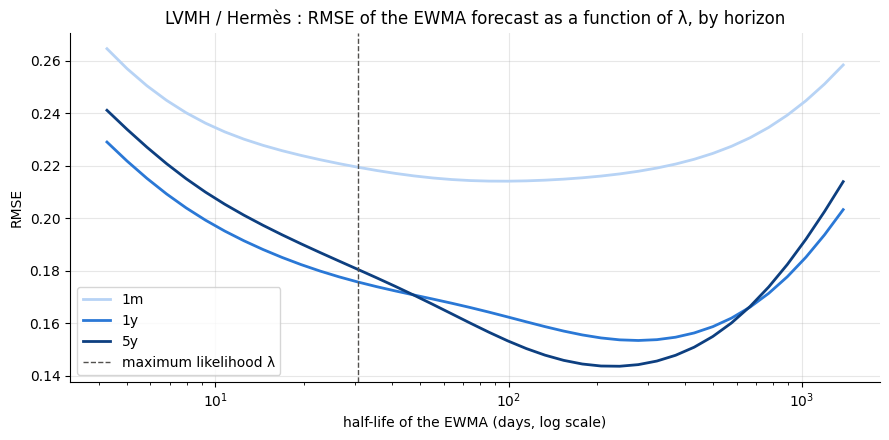

In [9]:
best = pd.DataFrame({name: res["rmse_lambda"].idxmin() for name, res in results.items()}).T[list(HORIZONS)]
hl = best.apply(half_life)
display(pd.DataFrame({"likelihood λ": lambdas["lambda (in-sample)"].median(), **best.median().to_dict()}, index=["median λ"])
        .T.assign(**{"half-life (days)": lambda d: half_life(d["median λ"])}).T.style.format("{:.4f}")
        .set_caption("λ minimising the RMSE by horizon (median over the baskets)"))

fig, ax = plt.subplots(figsize=(9, 4.5))
name = "LVMH / Hermès"
curves = results[name]["rmse_lambda"]
for h, c in [("1m", "#b7d3f5"), ("1y", "#2a78d6"), ("5y", "#0d3f80")]:
    ax.plot(half_life(curves.index), curves[h], color=c, lw=2, label=h)
ax.axvline(half_life(results[name]["lambda"]), color="#52514e", ls="--", lw=1, label="maximum likelihood λ")
ax.set_xscale("log"); ax.set_xlabel("half-life of the EWMA (days, log scale)"); ax.set_ylabel("RMSE")
ax.set_title(f"{name} : RMSE of the EWMA forecast as a function of λ, by horizon")
ax.legend(); plt.tight_layout(); plt.show()

## 6. The EWMA as a data-generating process

H0 : the residuals are generated by the EWMA recursion with the fitted λ (whitened innovations resampled i.i.d.,
200 paths per basket). The correlation of such a process has no anchor : over the length of the sample it spreads
over most of [−1, 1], whereas the observed correlations stay in a narrow positive band. Statistic : fraction of the
days where a conditional correlation exceeds 0.95 in absolute value, p = P_H0(fraction ≤ observed).

In [10]:
dyn = pd.DataFrame({k: v["dynamics"] for k, v in results.items()}).T
dyn["p (BH)"] = cc.benjamini_hochberg(dyn["p-value"])
dyn[["lambda", "observed rho min", "observed rho max", "H0 final rho 5%", "H0 final rho 95%", "H0 final rho |.| > 0.9",
     "days |rho| > 0.95 observed", "days |rho| > 0.95 H0 median", "p-value", "p (BH)"]]

,lambda,observed rho min,observed rho max,H0 final rho 5%,H0 final rho 95%,H0 final rho |.| > 0.9,days |rho| > 0.95 observed,days |rho| > 0.95 H0 median,p-value,p (BH)
LVMH / Hermès,0.9776,-0.1118,0.9175,-1,1,0.84,0,0.4946,0.07463,0.597
LVMH / Kering,0.9907,0.2657,0.8499,-0.8131,0.9967,0.375,0,0,0.602,0.995
LVMH / Hermès / Kering,0.992,0.03455,0.8873,-0.8473,0.9818,0.2533,0,0.000208,0.5025,0.995
BNP / SocGen,0.9875,0.1735,0.944,-0.8654,1,0.855,0,0.5835,0.08955,0.597
BNP / SocGen / Crédit Agricole,0.9875,0.1735,0.9567,-0.8901,1,0.72,0.000951,0.3258,0.03483,0.597
Airbus / Safran,0.994,0.284,0.8627,-0.2616,0.9218,0.07,0,0,0.9602,0.995
Airbus / Safran / Thales,0.992,0.1483,0.8761,-0.4751,0.9765,0.2583,0,0,0.602,0.995
L'Oréal / Danone,0.993,0.1667,0.8447,-0.6183,0.9318,0.1,0,0,0.9453,0.995
L'Oréal / Pernod,0.994,0.02984,0.7785,-0.8174,0.796,0.035,0,0,0.99,0.995
Vinci / Bouygues / Saint-Gobain,0.993,0.1716,0.8698,-0.7795,0.9379,0.1183,0,0,0.801,0.995


**Reading.** As a data-generating process the EWMA puts the correlation at the end of the sample anywhere between
≈ −0.85 and +0.99 (5 %-95 %), with |ρ| > 0.9 in up to 85 % of the paths, while the observed correlations stay
positive and below 0.96. Yet the test only rejects for one basket before correction and none after : the H0
distribution is too wide for any test against it to have power. This is why the EWMA is judged as a forecast
(sections 3-5) and not, as the constant was, against simulations of itself.

## 7. Conclusions

**The EWMA beats the constant at short horizons only.** Out-of-sample, the median RMSE of the EWMA is 0.225 at
1 month against 0.247 for the constant, 0.169 against 0.186 at 3 months ; the advantage disappears around 1 year
(0.148 against 0.151) and reverses at 5 years (0.148 against 0.142). Diebold-Mariano, after Benjamini-Hochberg :
the EWMA is significantly better for 11 baskets out of 20 at 1 month, 5 at 3-6 months, 1 at 1 year and none beyond ;
the constant is significantly better for 1 to 4 baskets from 1 year on.

**It does not approximate the realised correlation better at long horizons.** The excess RMSE (error not due to
sampling noise) of the EWMA is 0.12 at 1 month and grows to 0.14 at 5 years, the same as the constant's
(0.14) : neither tracks the slow level shifts of the correlation, and the residual error of about ±0.13-0.14 on the
correlation of a 1- to 5-year product remains.

**The EWMA over-reacts.** The Mincer-Zarnowitz slope b is 0.65 at 1 month and falls to 0.22 at 5 years (1 for an
unbiased forecast), with an intercept a of 0.20 to 0.46 : the realised correlation moves only a fraction of what the
EWMA moves, and the longer the horizon the more the best forecast shrinks the EWMA towards a long-run level.
(a, b) = (0, 1) is rejected for 17 to 20 baskets out of 20 at every horizon.

**The likelihood λ is too fast for pricing.** Maximum likelihood gives λ ≈ 0.992 (half-life ≈ 86 days, 31 days for
LVMH / Hermès) : it is the λ that best predicts tomorrow's correlation. The λ that minimises the error over the life
of the product is slower : ≈ 0.993 (half-life ≈ 100 days) at 1 month up to ≈ 0.996 (≈ 190 days) at 2-3 years.

**Consequence for pricing.** For short maturities (≤ 6 months) the EWMA is a better input than the historical
constant. Beyond 1 year it brings nothing : its forecast should be shrunk towards a long-run correlation, with a
weight on the EWMA that decreases with the maturity (b from 0.65 to 0.2), which is what the mean-reverting models of
`correlation_models.py` (DCC, blend of a short and a long window) do. Whatever the model, the correlation of a long
worst-of / best-of remains uncertain by ≈ ±0.14.